## Pricing a European call: Black–Scholes vs Monte Carlo

Inputs: $S = 100$, $K = 102$, $T = 3$ years, $r = 10\%$, $\sigma = 20\%$.
A **call** is the right to buy the stock at price $K$ at time $T$.

### 1. Black–Scholes formula (exact)

`black_scholes_call(S, K, T, r, sigma)` returns the **fair price today** of a European call,
the right to buy the stock at price $K$ at time $T$. It is the **no-arbitrage price**: at this
price, nobody can make a risk-free profit, so arbitrageurs have no opportunity to exploit.
It is derived by hedging the option with shares so that the portfolio is risk-free; a
risk-free portfolio must earn the risk-free rate $r$, and that condition fixes the price.

$$
C = S\,N(d_1) - K e^{-rT} N(d_2)
$$

$$
d_1 = \frac{\ln(S/K) + (r + \tfrac12\sigma^2)T}{\sigma\sqrt T},
\qquad
d_2 = d_1 - \sigma\sqrt T
$$

- $N(\cdot)$ is the standard normal CDF (`norm.cdf`).
- $N(d_2)$: risk-neutral probability the option ends in the money ($S_T > K$).
- $N(d_1)$: the option's Delta, the number of shares needed to hedge it.
- Reading the formula: **what you expect to receive** ($S\,N(d_1)$) minus
  **what you expect to pay** ($K e^{-rT} N(d_2)$), both valued today.
- Here: $d_1 = 0.982$, $d_2 = 0.636$, so $C = 27.97$.

In the code, `bs = black_scholes_call(S, K, T, r, sigma)` stores this price (27.97). It is used
in two ways:
1. **As the benchmark** for the Monte Carlo: the simulated price should converge to `bs`.
2. **As the premium** the buyer pays: profit on each path = discounted payoff − `bs`.

### 2. Monte Carlo (simulation)

**Stock price at expiry.** Under the risk-neutral measure, the stock follows
geometric Brownian motion with drift $r$: $dS = rS\,dt + \sigma S\,dW$.
Itô's lemma gives the exact solution:

$$
S_T = S \exp\!\Big[\big(r - \tfrac12\sigma^2\big)T + \sigma\sqrt T\, Z\Big],
\qquad Z \sim N(0,1)
$$

The drift is $r$, not the real expected return $\mu$: because the option can be hedged,
its price does not depend on $\mu$.

**Discounted payoff** on each path:

$$
X_i = e^{-rT}\max(S_T^{(i)} - K,\ 0)
$$

Here $e^{-rT} = 0.741$, so a payoff of 48 in 3 years is worth 35.56 today.

**Price** = average over $N$ paths (law of large numbers):

$$
\hat C = \bar X = \frac1N \sum_{i=1}^N X_i \;\longrightarrow\; C
$$

**Standard error of the mean:**

$$
\text{SE} = \frac{s}{\sqrt N},
\qquad s = \text{sample std of } X_i \ (\texttt{ddof=1})
$$

The error shrinks like $1/\sqrt N$: 100× more paths → 10× more precise.

### 3. Validation check

By the central limit theorem, $\bar X \approx N(C,\ \text{SE}^2)$, so

$$
z = \frac{|\bar X - C|}{\text{SE}}
$$

- $z < 2$: difference consistent with random noise (95% of runs).
- $z > 3$: unlikely by chance → probably a bug or bias.

In our runs, $z$ stayed below 2 for every $N$, and SE fell by about $\sqrt{10} \approx 3.16$
for each tenfold increase in paths, so the Monte Carlo agrees with Black–Scholes.

### 4. Where does the real expected return $\mu$ come in?

In the real world, the stock is expected to grow at $\mu$, usually above $r$:

$$
dS = \mu S\,dt + \sigma S\,dW
$$

**For pricing, $\mu$ drops out.** Hedging the option with Delta shares cancels the randomness,
and the hedged portfolio must earn $r$. So $\mu$ appears in neither the Black–Scholes formula
nor the Monte Carlo pricer, which simulates the stock with drift $r$
(the **risk-neutral** world).

**For risk, $\mu$ matters.** To forecast real outcomes, such as the buyer's chance of profit or
VaR, simulate the stock with $\mu$, but still discount with $r$:

$$
S_T = S \exp\!\Big[\big(\mu - \tfrac12\sigma^2\big)T + \sigma\sqrt T\, Z\Big],
\qquad
\text{profit}_i = e^{-rT}\max(S_T^{(i)} - K,\ 0) - C
$$

| | Risk-neutral (drift $r = 10\%$) | Real world (drift $\mu = 15\%$) |
|---|---|---|
| Buyers with a profit | 39.2% | 56.4% |
| Average profit | $\approx 0$ | 14.36 |

**Pricing uses risk-neutral probabilities; risk uses real-world probabilities.**

### Nomenclature:

1. Hedging the option means holding shares of the stock so that gains and losses on the shares cancel the gains and losses on the option.
2. VaR (Value at Risk) answers: How much could we lose over a given period, at a given level of confidence? The loss that won't be exceeded with a chosen probability

In [ ]:
import numpy as np
from scipy.stats import norm
import pandas as pd

rng = np.random.default_rng(1)

# 1. Price a European call option using the Black-Scholes formula
# this is the Black-Scholes predicted formula for risk free for a call option 
# that gives you the oportunity to buy a stock at a certain price in the future
def black_scholes_call(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    call_price = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return call_price

# 2. Simulate stock price paths using Geometric Brownian Motion
def monte_carlo_call(S, K, T, r, sigma, n_paths, rng):
    """European call price by Monte Carlo, with standard error."""
    Z = rng.standard_normal(n_paths)
    ST = S * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    # how much you get paid at the end of the option, discounted to present value
    disc_payoff = np.exp(-r * T) * np.maximum(ST - K, 0.0) 

    # return the standard error of the mean, which is the standard deviation divided by the square root of the number of paths
    return disc_payoff.mean(), disc_payoff.std(ddof=1) / np.sqrt(n_paths), disc_payoff

S, K, T, r, sigma = 100.0, 102.0, 3.0, 0.1, 0.20
bs = black_scholes_call(S, K, T, r, sigma)
print(f"Black-Scholes: {bs:.4f}")
for n in [1_000, 10_000, 100_000, 1_000_000]:
    mean, se, _ = monte_carlo_call(S, K, T, r, sigma, n, rng)
    print(f"N={n:>9,}  MC={mean:.4f}  SE={se:.4f}  |error|/SE={abs(mean-bs)/se:.2f}")

Black-Scholes: 27.9686
N=    1,000  MC=26.1863  SE=0.9751  |error|/SE=1.83
N=   10,000  MC=27.6474  SE=0.3181  |error|/SE=1.01
N=  100,000  MC=27.8623  SE=0.1009  |error|/SE=1.05
N=1,000,000  MC=27.9494  SE=0.0319  |error|/SE=0.60


I validated the Monte Carlo pricer against the Black–Scholes formula. The error stayed within two standard errors at every sample size, and the standard error fell by about √10 for each tenfold increase in paths, so the implementation is consistent with the theory.

If we rerun the whole simulation many times, the Monte Carlo means form an approximately normal distribution centred on the Black–Scholes price, with standard deviation equal to the standard error:

$$
\bar X \approx N\!\left(BS,\ \text{SE}^2\right), \qquad \text{SE} = \frac{\sigma}{\sqrt N}
$$

                          Real world (mu = 5%) Risk-neutral (r = 10%) Real world (mu = 15%) Real world (mu = 20%)
Options exercised                        58.0%                  73.6%                 85.8%                 93.3%
Option not exercised                     42.0%                  26.4%                 14.2%                  6.7%
Buyers with a profit                     24.1%                  39.3%                 56.4%                 72.3%
Average profit per option               -10.79                   0.05                 14.36                 32.18
Typical (median) buyer                  -22.53                  -9.43                  5.80                 23.50


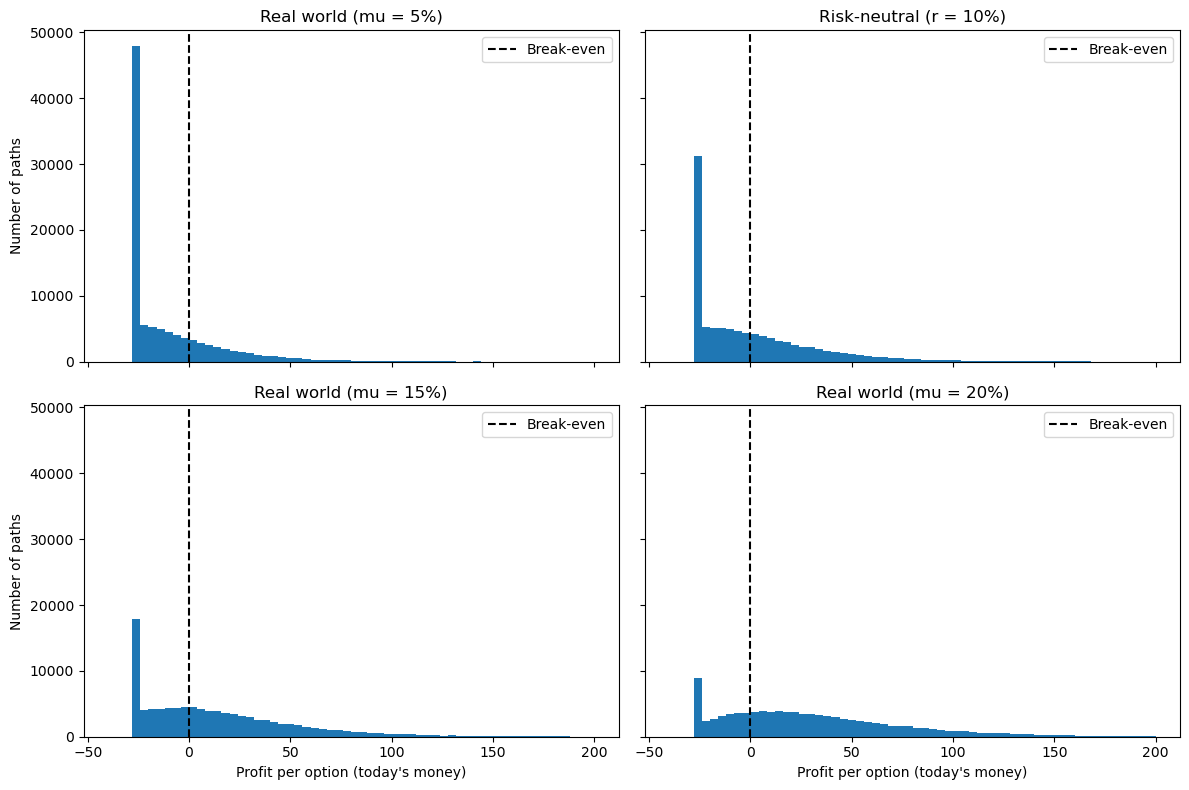

In [23]:
import matplotlib.pyplot as plt

n = 100_000
Z = rng.standard_normal(n)          # same random numbers for both worlds

worlds = {
    "Real world (mu = 5%)": 0.05,
    f"Risk-neutral (r = {r:.0%})": r,
    "Real world (mu = 15%)": 0.15,
    "Real world (mu = 20%)": 0.20,
}
results, profits = {}, {}

for name, drift in worlds.items():
    ST = S * np.exp((drift - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    payoffs = np.exp(-r * T) * np.maximum(ST - K, 0.0)   # always discount with r
    profit = payoffs - bs                                # minus the premium paid
    profits[name] = profit
    results[name] = {
        "Options exercised": f"{np.mean(payoffs > 0):.1%}",
        "Option not exercised": f"{np.mean(payoffs == 0):.1%}",
        "Buyers with a profit": f"{np.mean(profit > 0):.1%}",
        "Average profit per option": f"{profit.mean():.2f}",
        "Typical (median) buyer": f"{np.median(profit):.2f}",
    }

pd.set_option("display.max_columns", None)   # show all four columns
pd.set_option("display.width", 200)
print(pd.DataFrame(results))

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (name, profit) in zip(axes.flatten(), profits.items()):
    ax.hist(profit, bins=60, range=(-40, 200))
    ax.axvline(0, color="black", linestyle="--", label="Break-even")
    ax.set_title(name)
    ax.legend()
for ax in axes[1]:                 # bottom row: x labels
    ax.set_xlabel("Profit per option (today's money)")
for ax in axes[:, 0]:              # left column: y labels
    ax.set_ylabel("Number of paths")
plt.tight_layout()
plt.show()


### Explaining the option to a client, as a share of the premium

Measure each outcome as the **excess return** on the premium: how much better or worse the
option did than putting the same money in a risk-free account, over its whole 3-year life:

$$
\text{excess return} = \frac{e^{-rT}\max(S_T - K,\ 0) - C}{C}, \qquad C = 27.97
$$

Discounting at $r$ is what makes 0% mean **"the same as the risk-free account"**; positive means
better, negative means worse. This is a 3-year figure, not an annual rate, so it should not be
compared directly with $r$ or $\mu$, which are per year.

| | μ = 5% | Risk-neutral (r = 10%) | μ = 15% | μ = 20% |
|---|---|---|---|---|
| Chance of losing the **whole** premium (−100%) | 42% | 26% | 14% | 7% |
| Chance of beating the risk-free account | 24% | 39% | 56% | 72% |
| Median return | −81% | −34% | +21% | +84% |
| Average return | −39% | ≈ 0% | +51% | +115% |

- The **risk-neutral** column is the world used to **price** the option: the average return is
  zero, which is what a fair price means.
- The **real-world** columns forecast actual outcomes, but depend on the stock's expected
  return $\mu$, which cannot be observed. The price is £27.97 in every column; only the outcomes change.

**How I would communicate this risk to a non-specialist:**
- **The price is the same whatever you expect:** the option is priced in a risk-neutral world,
  where every stock grows at the same risk-free rate $r$ (10% here). So the price (£27.97) depends
  on the stock's volatility $\sigma$, but not on how fast you expect it to grow.
- **Real outcomes depend on the stock:** in reality, each stock has its own expected return $\mu$,
  which reflects how risky it is, and it cannot be observed, only estimated.
- **Lead with the downside:** "Depending on how the stock performs, between 7% and 42% of buyers
  (roughly 1 in 15 to 2 in 5) lose everything they paid."
- **Give the typical outcome, not just the average:** "With 15% growth, the middle outcome is
  about +21%; the +51% average is pulled up by a few very large gains."
- **Show a range, not one number:** the results swing from an average of −39% to +115% depending
  on the assumed growth rate. A single figure would hide that uncertainty.
- **What makes an option attractive on average:** a call only beats the risk-free account on
  average if the stock's expected return is above $r$ (in our table, μ = 15% and 20% do; μ = 5%
  does not). But stocks with higher expected returns are usually riskier, so there is no free lunch.
- **Compare with the alternative:** a risk-free account earns 10% a year with no chance of loss;
  the option offers higher potential gains with a real chance of losing it all.
- **The maximum loss is the full premium,** so it should only be money the client can afford to lose.

In [ ]:
def bs_delta(S, K, tau, r, sigma):
    """Black-Scholes call Delta = N(d1): shares to hold per option, with time to expiry tau."""
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    return norm.cdf(d1)

def seller_pnl(mu, sigma_real, steps, n, rng):
    """Bank sells one call at the Black-Scholes price bs and delta-hedges with the assumed sigma;
    the stock really moves with mu and sigma_real. Returns hedged and unhedged P&L per option."""
    dt = T / steps
    St = np.full(n, S)                            # every path starts at today's price
    delta = bs_delta(St, K, T, r, sigma)          # assumed sigma
    cash = bs - delta * St                        # receive premium, buy Delta shares
    for i in range(1, steps + 1):
        Z = rng.standard_normal(n)
        St = St * np.exp((mu - 0.5 * sigma_real**2) * dt + sigma_real * np.sqrt(dt) * Z)  # real sigma
        cash = cash * np.exp(r * dt)              # cash earns interest
        if i < steps:                             # rebalance to the new Delta
            new_delta = bs_delta(St, K, T - i * dt, r, sigma)
            cash -= (new_delta - delta) * St
            delta = new_delta
    payoff = np.maximum(St - K, 0.0)
    hedged = (cash + delta * St - payoff) * np.exp(-r * T)
    unhedged = bs - payoff * np.exp(-r * T)
    return hedged, unhedged

def risk_stats(pnl):
    """Bank's P&L convention: negative = loss."""
    var99 = np.quantile(pnl, 0.01)          # worst 1% starts here
    es99 = pnl[pnl <= var99].mean()         # average of the worst 1%
    return {"Average P&L": f"£{pnl.mean():.1f}", "99% VaR": f"£{var99:.1f}", "99% ES": f"£{es99:.1f}"}

mu, n = 0.15, 50_000
hedged_weekly, unhedged = seller_pnl(mu, sigma_real=0.20, steps=156, n=n, rng=rng)
hedged_daily, _ = seller_pnl(mu, sigma_real=0.20, steps=756, n=n, rng=rng)
hedged_vol30, _ = seller_pnl(mu, sigma_real=0.30, steps=156, n=n, rng=rng)

table = pd.DataFrame({
    "Unhedged (real vol 20%)": risk_stats(unhedged),
    "Delta-hedged, weekly (real vol 20%)": risk_stats(hedged_weekly),
    "Delta-hedged, daily (real vol 20%)": risk_stats(hedged_daily),
    "Delta-hedged, weekly (real vol 30%)": risk_stats(hedged_vol30),
}).T
print(table)

                                    Average P&L  99% VaR   99% ES
Unhedged (real vol 20%)                  £-14.6  £-142.3  £-176.4
Delta-hedged, weekly (real vol 20%)       £-0.0    £-1.6    £-2.1
Delta-hedged, daily (real vol 20%)        £-0.0    £-0.8    £-1.0
Delta-hedged, weekly (real vol 30%)       £-4.4   £-11.6   £-12.9


### Why measure unhedged risk if banks hedge?

#### Definitions

- **Hedging:** holding a second position whose gains and losses offset those of the first.
- **Delta ($\Delta$):** the number of shares held per option to hedge it; equivalently, how much
  the option price changes for a £1 move in the stock. For a Black–Scholes call with time to
  expiry $\tau = T - t$:
$$
\Delta_t = \frac{\partial C}{\partial S} = N(d_1),
\qquad
d_1 = \frac{\ln(S_t/K) + (r + \tfrac12\sigma^2)\tau}{\sigma\sqrt\tau}
$$
- **Delta hedging:** the bank that sells the call holds $\Delta_t$ shares, so small moves in the
  stock cancel out between the option and the shares.
- **Rebalancing:** $\Delta_t$ changes as the stock and time move, so the bank buys or sells shares
  at regular intervals (here weekly or daily) to keep the hedge right.
- **Self-financing:** no money is added or taken out. Share purchases are paid from a cash
  account that earns (or pays) the risk-free rate $r$.
- **Gamma ($\Gamma$):** how fast Delta changes, $\Gamma = \partial^2 C / \partial S^2$. A seller of
  options is **short gamma**: large moves in either direction hurt.

#### The hedging strategy, step by step

Split the 3 years into $n$ steps of length $\Delta t = T/n$ (weekly: $n = 156$).

**1. Start:** receive the premium $C$ and buy $\Delta_0$ shares:
$$
B_0 = C - \Delta_0 S_0
$$
where $B$ is the cash account (negative means borrowing).

**2. Each step:** the stock moves in the **real world**, with drift $\mu$ and true volatility
$\sigma_{\text{real}}$:
$$
S_{t+\Delta t} = S_t \exp\!\Big[\big(\mu - \tfrac12\sigma_{\text{real}}^2\big)\Delta t
+ \sigma_{\text{real}}\sqrt{\Delta t}\, Z\Big], \qquad Z \sim N(0,1)
$$
The cash earns interest, and the bank rebalances to the new Delta (computed with the
**assumed** volatility $\sigma$):
$$
B_{t+\Delta t} = B_t\, e^{r\Delta t} - \big(\Delta_{t+\Delta t} - \Delta_t\big)\, S_{t+\Delta t}
$$

**3. Expiry:** the bank holds its shares and cash, and pays the option payoff (P \& L stands for profit and loss):
$$
\text{Hedged P\&L} = e^{-rT}\Big[B_T + \Delta_T S_T - \max(S_T - K,\ 0)\Big]
$$

**Unhedged**, the bank simply keeps the premium and pays the payoff:
$$
\text{Unhedged P\&L} = C - e^{-rT}\max(S_T - K,\ 0)
$$

#### Why the hedged result does not depend on $\mu$

The seller holds $-1$ call, $\Delta$ shares and cash $B$: $\ \Pi = -C + \Delta S + B$.
Over a small time step,
$$
d\Pi = -dC + \Delta\, dS + rB\, dt
$$
By Itô's lemma, $dC = C_t\, dt + C_S\, dS + \tfrac12 C_{SS}\,(dS)^2$. Choosing
$\Delta = C_S$ cancels the $dS$ terms:
$$
d\Pi = -C_t\, dt - \tfrac12 \Gamma\,(dS)^2 + rB\, dt,
\qquad (dS)^2 = \sigma_{\text{real}}^2 S^2\, dt
$$
The drift $\mu$ only enters through $dS$, which has cancelled, so the hedged position does not
depend on $\mu$: only the size of the moves (volatility) matters.

#### Why the hedge fails when volatility is wrong

The option is priced with volatility $\sigma$, so it satisfies the Black–Scholes PDE
$C_t = rC - rS\Delta - \tfrac12\sigma^2 S^2 \Gamma$. With $B = C - \Delta S$, this gives
$$
d\Pi = \tfrac12\, \Gamma\, S^2 \big(\sigma^2 - \sigma_{\text{real}}^2\big)\, dt
$$
If $\sigma_{\text{real}} = \sigma$, the hedge is perfect. If $\sigma_{\text{real}} > \sigma$,
the seller loses a little at every step.

#### Why the hedge fails when volatility is wrong

If the stock is really more volatile than assumed, the seller's hedged P&L is approximately
$$
\text{P\&L} \approx \sum_t \tfrac12\, \Gamma_t\, S_t^2 \big(\sigma^2 - \sigma_{\text{real}}^2\big)\,\Delta t
\;<\; 0 \quad \text{when } \sigma_{\text{real}} > \sigma
$$
so a short-gamma seller loses steadily on almost every path.

#### Risk measures

With the seller's loss $L = -\text{P\&L}$:
$$
P\big(L > \text{VaR}_\alpha\big) = 1 - \alpha,
\qquad
\text{ES}_\alpha = E\big[L \mid L \ge \text{VaR}_\alpha\big]
$$

#### Results ($\mu = 15\%$, priced at $\sigma = 20\%$, per option, in today's money)

| Seller's position | Average P&L | 99% VaR (worst 1% starts at) | 99% ES (average of worst 1%) |
|---|---|---|---|
| Unhedged | −£14.6 | −£143 | −£177 |
| Delta-hedged, weekly | ≈ £0 | −£1.7 | −£2.2 |
| Delta-hedged, daily | ≈ £0 | −£0.8 | −£1.0 |
| Hedged weekly, $\sigma_{\text{real}} = 30\%$ | −£4.4 | −£11.7 | −£13.0 |

All figures are the bank's profit per option, in today's money; a minus sign means a loss.
- **When the real volatility is higher than the assumed one used to price the option and compute
  $\Delta$** ($\sigma_{\text{real}} > \sigma$), the stock moves more than the hedge expects, so the
  hedged seller's P&L is **negative**: about −£4.4 on average with $\sigma_{\text{real}} = 30\%$
  vs $\sigma = 20\%$, and the 99% VaR worsens from −£1.7 to −£11.7.
- **VaR (Value at Risk):** in only 1% of scenarios does the bank do worse than this.
- **ES (Expected Shortfall):** the bank's average result in that worst 1%.
- **Hedging removes almost all the risk**; what remains comes from rebalancing discretely
  rather than continuously, and shrinks with more frequent rebalancing.
- **The hedged result does not depend on μ**: the average is about zero even though the stock
  is expected to grow at 15%.
- **The remaining risk is in the assumptions**: if volatility is higher than assumed, the hedged
  position loses on almost every path and its VaR rises about sevenfold. This is model risk,
  managed with vega limits and volatility stress tests.
- **The unhedged VaR** sizes the exposure the hedge must remove, and matters in a stress scenario
  where hedging becomes impossible (a market freeze or price gap).
- **Where the two volatilities enter the calculation:**
  - **Assumed volatility $\sigma = 20\%$** is the bank's model. It sets the **premium**
    $C = 27.97$ (Black–Scholes formula) and the **hedge** $\Delta_t = N(d_1)$ at every rebalancing
    step, through $d_1 = \frac{\ln(S_t/K) + (r + \frac12\sigma^2)\tau}{\sigma\sqrt\tau}$.
    In code: `bs_call_delta(..., sigma)`.
  - **Real volatility $\sigma_{\text{real}}$** is how the stock actually moves. It only enters the
    **simulation of the stock**:
    $S_{t+\Delta t} = S_t \exp\big[(\mu - \frac12\sigma_{\text{real}}^2)\Delta t
    + \sigma_{\text{real}}\sqrt{\Delta t}\,Z\big]$. In code: `sigma_real` in the price update.
  - When $\sigma_{\text{real}} = \sigma$, the hedge matches the moves and the P&L is about zero.
    When $\sigma_{\text{real}} > \sigma$, the stock moves more than the hedge expects, and the
    seller loses about $\tfrac12\,\Gamma S^2(\sigma_{\text{real}}^2 - \sigma^2)$ per unit of time.

## Bachelier model: prices that can go negative

**Black–Scholes** assumes prices move by **percentages**, so the log of the price is normal and
the price can never go negative:
$$
dS = \mu S\,dt + \sigma S\,dW
\quad\Rightarrow\quad
\ln S_T \sim N\!\big(\ln S_0 + (\mu - \tfrac12\sigma^2)T,\ \sigma^2 T\big)
$$

**Bachelier** assumes prices move by **fixed amounts**, so the price itself is normal and can go
negative. For a futures price $F$ under the risk-neutral measure (no drift):
$$
dF = \sigma_N\,dW
\quad\Rightarrow\quad
F_T = F_0 + \sigma_N\sqrt T\,Z \sim N\!\big(F_0,\ \sigma_N^2 T\big)
$$
Here $\sigma_N$ is the **normal volatility**, in price units (dollars), not percent.
In both models the volatility is constant.

**Bachelier call price:**
$$
C = e^{-rT}\Big[(F_0 - K)\,N(d) + \sigma_N\sqrt T\; n(d)\Big],
\qquad
d = \frac{F_0 - K}{\sigma_N\sqrt T}
$$
where $N$ is the standard normal CDF and $n$ its density (`norm.pdf`).

**Chance of a negative price:**
$$
P(F_T < 0) = N\!\left(-\frac{F_0}{\sigma_N\sqrt T}\right)
$$

**Where it is used:** interest-rate options (rates went negative in Europe and Japan), and oil
options after US oil futures settled at about −\$37 in April 2020. 

## Interest-rate options: an example

### What they are

**Interest-rate options** pay out based on an **interest rate** rather than a stock price.
Buying one is like **buying insurance against rates moving the wrong way**: you pay a premium
upfront, and the seller (usually a bank) pays you cash if rates move past a set level.
Unlike a stock option, nothing is bought or sold at expiry: they are **cash-settled**.


### Example: buying a cap

A company has a **£10m loan** at a floating rate that resets every 3 months. Worried that rates
will rise, it **buys a 3-year cap at 4%** and pays a premium upfront (£95,049, priced in the next
section).

A cap is a series of **caplets**, one per quarter. Each pays

$$
\text{caplet payoff} = N \times \tau \times \max(L - K,\ 0)
$$

where $N = £10\text{m}$ is the notional, $\tau = 0.25$ the length of the period, $L$ the reference
rate that quarter and $K = 4\%$ the cap rate.

| Rate that quarter $L$ | Extra interest above 4% | Cap pays the company | Effective rate paid |
|---|---|---|---|
| 3% | none | £0 | 3% |
| 5% | £25,000 | £25,000 | 4% |
| 7% | £75,000 | £75,000 | 4% |

The company's borrowing cost **never exceeds 4%** (plus its loan margin), but if rates stay low
it still benefits. The cost is the premium, lost if rates never rise above 4%.

**Cap vs fixing the rate:** the company could instead fix its rate with an interest rate swap, at
no upfront cost, but then it would not benefit if rates fell. The cap gives protection while
keeping the benefit of lower rates, for a premium: the same trade-off as the farmer choosing
between a forward and a put option.

In [35]:
# Interest-rate cap: scenarios for one quarter
N = 10_000_000      # notional (loan size), £
tau = 0.25          # length of each period: 3 months
K_cap = 0.04        # cap rate: 4%

for L in [0.03, 0.05, 0.07]:
    payoff = N * tau * max(L - K_cap, 0)
    print(f"Rate {L:.0%}: cap pays £{payoff:,.0f}, effective rate {min(L, K_cap):.0%}")

Rate 3%: cap pays £0, effective rate 3%
Rate 5%: cap pays £25,000, effective rate 4%
Rate 7%: cap pays £75,000, effective rate 4%


## Pricing the cap: caplets, the Bachelier model and risk

### 1. What a caplet is

A company borrows **£10m for 3 years**. The interest rate on the loan **changes every quarter**,
so the company does not know in advance how much interest it will pay. Each quarter it pays
$A\,\tau\,L_i$, where $L_i$ is that quarter's interest rate. Its worry is rates rising.

To protect itself, it buys a **cap**: a bundle of small options, one for each future quarter. Each
is a **caplet**, which pays the company whenever that quarter's rate is above the cap rate $K$:

$$
\text{caplet payoff}_i = A\,\tau\,\max(L_i - K,\ 0)
$$

So the company never pays more than $K$. The cap price is the sum of the caplet prices:

$$
\text{cap price} = \sum_{i} \text{caplet}_i
$$

| Symbol | Meaning | Value |
|---|---|---|
| $A$ | Amount borrowed | £10m |
| $\tau$ | Length of each quarter | 0.25 years |
| $K$ | Cap rate: the most the company will pay | 4% |
| $L_i$ | Interest rate for quarter $i$, unknown today | random |
| $r$ | Risk-free rate, used for discounting | 4% |
| $\sigma_N$ | Volatility of the interest rate | 0.8% a year |

### 2. The timeline of each caplet

Each reset of the loan rate is a new, separate risk, so the cap gives one caplet per quarter, with
the same dates and notional as the loan. Each quarter has two dates: the rate is **set** at the
start, $T_i$, and the interest is **paid** at the end, $T_i + \tau$.

| Caplet | Quarter covered (years) | Rate set at $T_i$ | Paid at $T_i + \tau$ |
|---|---|---|---|
| — | 0 to 0.25 | today (already known) | no caplet needed |
| 1 | 0.25 to 0.50 | 0.25 | 0.50 |
| 2 | 0.50 to 0.75 | 0.50 | 0.75 |
| ... | ... | ... | ... |
| 11 | 2.75 to 3.00 | 2.75 | 3.00 |

So there are **11 caplets**, with $T_i = 0.25, 0.50, \dots, 2.75$ years: 12 quarters, minus the
first, whose rate is already known today.

### 3. The forward rate $F$

The caplet pays on a rate that is not known yet, so we need its **fair, no-arbitrage value as seen
from today**: the **forward rate** $F_i$, the rate for that future quarter that can be locked in
today.

At the risk-free rate $r$, **£1 invested today grows to $e^{rT}$ by time $T$**. Compare two ways
of investing £1 until the end of the quarter, $T_i + \tau$:

- **Directly:** £1 grows to $e^{r(T_i + \tau)}$.
- **In two steps:** £1 grows to $e^{rT_i}$ by the start of the quarter, then earns the locked-in
  rate $F_i$ for the quarter: $e^{rT_i}\,(1 + F_i\tau)$.

Both are risk-free, so they must give the same amount, otherwise there is an arbitrage:

$$
e^{r(T_i + \tau)} = e^{rT_i}\,(1 + F_i\tau)
\quad\Rightarrow\quad
F_i = \frac{e^{r\tau} - 1}{\tau}
$$

With $r = 4\%$ and $\tau = 0.25$: $F_i = (e^{0.01} - 1)/0.25 \approx 4.02\%$, which we round to
**$F = 4\%$** for every quarter. (In reality, rates differ by maturity, so each quarter has its own
forward rate, read from today's market rates.)

### 4. The model: how the future rate is distributed

The **Bachelier (normal) model** assumes the rate moves by normally distributed **amounts**, with
no drift:

$$
dL = \sigma_N\,dW
\quad\Rightarrow\quad
L_i = F + \sigma_N W(T_i) \;\sim\; N\!\big(F,\ \sigma_N^2 T_i\big)
$$

- $dW$ is the random kick of a Brownian motion: $dW \sim N(0,\ dt)$, i.e. $dW = \sqrt{dt}\,Z$.
- **Mean $F$:** no drift, because $F$ is the fair value of the future rate.
- **Variance $\sigma_N^2 T_i$:** independent moves add up their variances, so the spread grows like
  $\sqrt{T_i}$, as in diffusion.
- $\sigma_N = 0.8\%$ (80 basis points) means the rate typically moves about ±0.8 percentage points
  a year; by 2.75 years the spread is about ±1.33 points.

**Why this model:** interest rates can go below zero (the European Central Bank's rate was −0.5%
from 2019 to 2022). Lognormal models like Black–Scholes cannot handle this; the normal
distribution can, which is why interest-rate options are priced with the Bachelier model.

### 5. The Bachelier caplet formula

Averaging the discounted payoff over this normal distribution gives:

$$
\text{caplet}_i = A\,\tau\,D_i\Big[(F - K)\,N(d_i) + \sigma_N\sqrt{T_i}\; n(d_i)\Big],
\qquad d_i = \frac{F - K}{\sigma_N\sqrt{T_i}}
$$

- $D_i = e^{-r(T_i + \tau)}$: discount factor to the **payment** date (the value today of £1 paid then).
- $\sigma_N\sqrt{T_i}$: uses the **fixing** date, because the rate is uncertain only until it is set.
- $N(\cdot)$ and $n(\cdot)$: standard normal CDF and density.

**At the money:** since $F = K = 4\%$, every caplet is **at the money** (about a 50/50 chance of
paying). Then $d_i = 0$, the first term vanishes, and $n(0) = 1/\sqrt{2\pi} \approx 0.399$:

$$
\text{caplet}_i = \frac{A\,\tau\,D_i\,\sigma_N\sqrt{T_i}}{\sqrt{2\pi}}
$$

The whole price comes from volatility: without it, the caplet would be worthless.

**Check, caplet fixing in 1 year:**
$\ £10\text{m} \times 0.25 \times e^{-0.05} \times 0.008 \times \sqrt{1} \times 0.399 \approx £7{,}590$.
In 1 year, that quarter's rate is set; if it is above 4%, the bank pays $A\tau(L_i - 4\%)$ three
months later. £7,590 is the fair value today of that possible payment.

### 6. Results

- Caplet prices rise from **£3,910** (fixing in 3 months) to **£11,735** (fixing in 2.75 years),
  because later rates have more time to move ($\sigma_N\sqrt{T_i}$ grows).
- **Cap price = £95,049**: the premium the company pays the bank upfront.

In [ ]:
import pandas as pd

# Inputs
A = 10_000_000      # amount borrowed: £10m
tau = 0.25          # length of each quarter
K_cap = 0.04        # cap rate: the most the company will pay, 4%
r_cap = 0.04            # risk-free rate, used for discounting: 4%
sigma_n = 0.008     # volatility of the interest rate: 0.8% a year

# Forward rate: (e^(r*tau) - 1) / tau ≈ 4.02%, rounded to 4% as in the text
F_exact = (np.exp(r_cap * tau) - 1) / tau
F = 0.04
print(f"Forward rate: {F_exact:.4%} (rounded to {F:.0%})")

def bachelier_caplet(F, K, T_fix, D, A, tau, sigma_n):
    """Price of one caplet in the Bachelier (normal) model."""
    d = (F - K) / (sigma_n * np.sqrt(T_fix))
    return A * tau * D * ((F - K) * norm.cdf(d) + sigma_n * np.sqrt(T_fix) * norm.pdf(d))

fix_times = np.arange(0.25, 3.0, 0.25)   # when each rate is set: 0.25, 0.5, ..., 2.75 years
pay_times = fix_times + tau              # each caplet pays 3 months after its rate is set
D = np.exp(-r_cap * pay_times)               # discount factors to the payment dates

caplets = bachelier_caplet(F, K_cap, fix_times, D, A, tau, sigma_n)
cap_price = caplets.sum()

print(f"Cap price: £{cap_price:,.0f} ({len(caplets)} caplets)")
print(pd.DataFrame({"Fixing (years)": fix_times, "Caplet price (£)": caplets.round(0)}).to_string(index=False))

Forward rate: 4.0201% (rounded to 4%)
Cap price: £95,049 (11 caplets)
 Fixing (years)  Caplet price (£)
           0.25            3910.0
           0.50            5475.0
           0.75            6639.0
           1.00            7590.0
           1.25            8401.0
           1.50            9111.0
           1.75            9744.0
           2.00           10313.0
           2.25           10829.0
           2.50           11302.0
           2.75           11735.0


### 7. Monte Carlo check

Each simulated path is one possible future for the loan rate. Starting from the forward rate (4%),
each quarter the rate moves by a normal amount:

$$
L_{i+1} = L_i + \sigma_N\sqrt{\tau}\,Z, \qquad Z \sim N(0,1)
$$

On each path, the 11 caplet payments $A\tau\max(L_i - K,\ 0)$ are discounted to today and added up;
the average over 100,000 paths is the Monte Carlo price.

| | Value |
|---|---|
| Formula price | £95,049 |
| Monte Carlo price | £95,279 (SE £371, so $\lvert\text{error}\rvert/\text{SE} \approx 0.6$) |
| Chance the cap pays at least once | 83% |
| Chance rates go negative at some point | 0.16% |

The simulation agrees with the formula within noise. Negative rates barely matter here: the cap
only pays above 4%, and starting from 4%, rates rarely fall below zero.

### 8. The bank's side

The bank that **sells** the cap receives the premium and must pay out if rates rise. Unhedged,
its P&L per cap is (negative = loss):

| | Value |
|---|---|
| Premium received | £95,049 |
| Average P&L | ≈ £0 (fair price) |
| 99% VaR (worst 1% starts at) | −£388,000 |
| 99% ES (average of worst 1%) | −£457,000 |

In the worst 1% of scenarios, the bank loses about four times the premium: a capped gain against
much larger potential losses. So it hedges this exposure, and its risk team measures what is left:
how much it could lose if rates jump, and how sensitive the result is to model assumptions such as
the volatility or the normal distribution of rates.

Formula price:      £95,049
Monte Carlo price:  £95,082 (SE £371, |error|/SE = 0.09)
Chance the cap pays at least once:      83.3%
Chance rates go negative at some point: 0.16%

Bank (unhedged), per cap:
Premium received:   £95,049
Average P&L:        £-33
99% VaR:            £-387,787
99% ES:             £-457,859


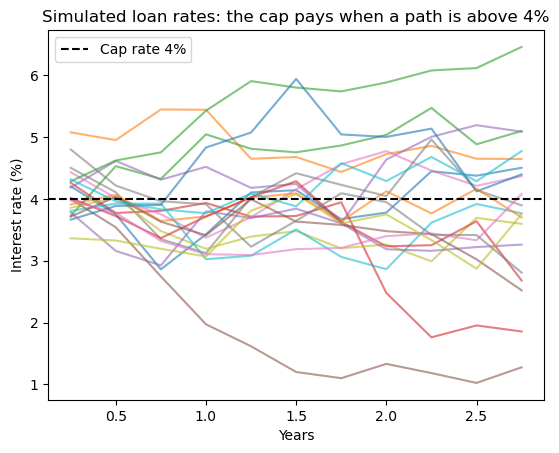

In [37]:
import matplotlib.pyplot as plt

# 7. Monte Carlo check
n = 100_000
Z = rng.standard_normal((n, len(fix_times)))

# Each quarter the rate moves by a normal amount: L_{i+1} = L_i + sigma_n * sqrt(tau) * Z
rates = F + sigma_n * np.sqrt(tau) * np.cumsum(Z, axis=1)

payments = A * tau * np.maximum(rates - K_cap, 0)   # caplet payments on each path
pv_payments = (payments * D).sum(axis=1)            # discounted to today and added up

mc_price = pv_payments.mean()
mc_se = pv_payments.std(ddof=1) / np.sqrt(n)
print(f"Formula price:      £{cap_price:,.0f}")
print(f"Monte Carlo price:  £{mc_price:,.0f} (SE £{mc_se:,.0f}, |error|/SE = {abs(mc_price - cap_price) / mc_se:.2f})")
print(f"Chance the cap pays at least once:      {np.mean(payments.sum(axis=1) > 0):.1%}")
print(f"Chance rates go negative at some point: {np.mean((rates < 0).any(axis=1)):.2%}")

# 8. The bank's side: sells the cap, receives the premium, pays the caplets (unhedged)
bank_pnl = cap_price - pv_payments
var99 = np.quantile(bank_pnl, 0.01)           # worst 1% starts here
es99 = bank_pnl[bank_pnl <= var99].mean()     # average of the worst 1%
print(f"\nBank (unhedged), per cap:")
print(f"Premium received:   £{cap_price:,.0f}")
print(f"Average P&L:        £{bank_pnl.mean():,.0f}")
print(f"99% VaR:            £{var99:,.0f}")
print(f"99% ES:             £{es99:,.0f}")

# Plot 20 simulated rate paths against the cap rate
plt.plot(fix_times, rates[:20].T * 100, alpha=0.6)
plt.axhline(K_cap * 100, color="black", linestyle="--", label="Cap rate 4%")
plt.xlabel("Years")
plt.ylabel("Interest rate (%)")
plt.title("Simulated loan rates: the cap pays when a path is above 4%")
plt.legend()
plt.show()